# Setup

In [1]:
# @title
!pip install -q -U transformers
!pip install -U protobuf

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.5/11.5 MB 100.7 MB/s eta 0:00:0000:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 327.1/327.1 kB 6.7 MB/s eta 0:00:00a 0:00:01
  Attempting uninstall: protobuf
    Found existing installation: protobuf 5.29.6
    Uninstalling protobuf-5.29.6:
      Successfully uninstalled protobuf-5.29.6
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
grpcio-status 1.71.2 requires protobuf<6.0dev,>=5.26.1, but you have protobuf 7.35.1 which is incompatible.
google-ai-generativelanguage 0.6.15 requires protobuf!=4.21.0,!=4.21.1,!=4.21.2,!=4.21.3,!=4.21.4,!=4.21.5,<6.0.0dev,>=3.20.2, but you have protobuf 7.35.1 which is incompatible.
ydf 0.15.0 requires protobuf<7.0.0,>=5.29.1, but you have protobuf 7.35.1 which is incompatible.


In [2]:
# @title
import tensorflow_datasets as tfds
import numpy as np
import pandas as pd
import cv2
from IPython import display
import sys
import seaborn as sns
import matplotlib.pyplot as plt
from collections import Counter
from skimage import data, color
from skimage.transform import rescale, resize, downscale_local_mean
from tensorflow.image import resize_with_pad, ResizeMethod
from sklearn.model_selection import train_test_split
from PIL import Image
import requests
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from transformers import pipeline
import torch
from accelerate.test_utils.testing import get_backend
from PIL import Image
import requests
import os

# Import Data

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
# import kagglehub

# # Download latest version
# path = kagglehub.dataset_download("mikoajkoek/traffic-road-object-detection-polish-12k")

In [5]:
# os.listdir(path)

In [6]:
# import shutil
# import os

# extract_dir = '/content/drive/My Drive/Dataset'

# os.makedirs(extract_dir, exist_ok=True)  # Safer directory creation
# shutil.move(path, extract_dir)

In [7]:
import os

base_dir = '/content/drive/My Drive/traffic-road-object-detection-polish-12k/road_detection/road_detection'
train_dir = os.path.join(base_dir, 'train')
val_dir = os.path.join(base_dir, 'valid')
test_dir = os.path.join(base_dir, 'test')

assert os.path.exists(base_dir), f"Base directory not found"
assert os.path.exists(train_dir), f"Train directory not found: {train_dir}"
assert os.path.exists(val_dir), f"Validation directory not found: {val_dir}"
assert os.path.exists(test_dir), f"Test directory not found: {test_dir}"

# traffic-road-object-detection-polish-12k/road_detection/road_detection

In [8]:
os.listdir(base_dir)

['test', 'valid', 'train']

# Process Data

In [9]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Create data generators with normalization
train_datagen = ImageDataGenerator(rescale=1./255)
val_datagen = ImageDataGenerator(rescale=1./255)
test_datagen = ImageDataGenerator(rescale=1./255)

train_data = next(train_datagen.flow_from_directory(
    # batch_size=32,
    directory=train_dir,
    shuffle=True,
    # target_size=(IMG_SHAPE, IMG_SHAPE),
    class_mode='categorical')
)

val_data = next(val_datagen.flow_from_directory(
    # batch_size=32,
    directory=val_dir,
    shuffle=False,
    # target_size=(IMG_SHAPE, IMG_SHAPE),
    class_mode='categorical')
)

test_data = next(test_datagen.flow_from_directory(
    # batch_size=32,
    directory=test_dir,
    shuffle=False,
    # target_size=(IMG_SHAPE, IMG_SHAPE),
    class_mode='categorical')
)

Found 10474 images belonging to 2 classes.
Found 935 images belonging to 2 classes.
Found 484 images belonging to 2 classes.


# Apply ZoeDepth Model

In [10]:
device, _, _ = get_backend()
checkpoint = "Intel/zoedepth-nyu-kitti"
pipe = pipeline("depth-estimation", model=checkpoint, device=device)

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
You are not authenticated with the Hugging Face Hub in this notebook.
If the error persists, please let us know by opening an issue on GitHub (https://github.com/huggingface/huggingface_hub/issues/new).
  warnings.warn(


config.json:   0%|          | 0.00/2.23k [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/1.38G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/647 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/723 [00:00<?, ?B/s]

In [11]:
test_data

(array([[[[0.        , 0.        , 0.        ],
          [0.        , 0.        , 0.        ],
          [0.        , 0.        , 0.        ],
          ...,
          [0.02352941, 0.02352941, 0.02352941],
          [0.03137255, 0.03137255, 0.03137255],
          [0.03529412, 0.03529412, 0.03529412]],
 
         [[0.        , 0.        , 0.        ],
          [0.        , 0.        , 0.        ],
          [0.        , 0.        , 0.        ],
          ...,
          [0.02352941, 0.02352941, 0.02352941],
          [0.03137255, 0.03137255, 0.03137255],
          [0.03921569, 0.03921569, 0.03921569]],
 
         [[0.        , 0.        , 0.        ],
          [0.        , 0.        , 0.        ],
          [0.        , 0.        , 0.        ],
          ...,
          [0.02352941, 0.02352941, 0.02352941],
          [0.03137255, 0.03137255, 0.03137255],
          [0.04313726, 0.04313726, 0.04313726]],
 
         ...,
 
         [[0.0627451 , 0.04705883, 0.00392157],
          [0.06274

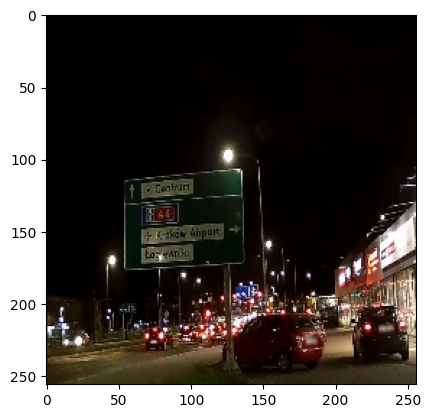

In [12]:
plt.imshow(test_data[0][1])

In [13]:
images_np = test_data[0]

# If the arrays are normalized to [0, 1], convert back to uint8
if images_np.dtype != "uint8":
    images_np = (images_np * 255).astype("uint8")

pil_images = [Image.fromarray(img) for img in images_np]

# Replace test_data tuple with PIL images in index 0
test_data = (pil_images, test_data[1])

In [14]:
predictions = pipe(test_data[0])


In [15]:
depths = [pred["depth"] for pred in predictions]

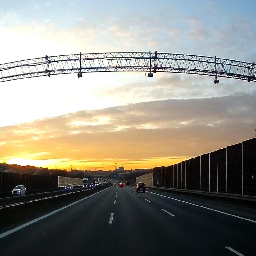

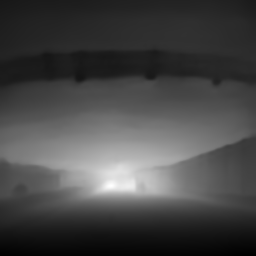

In [24]:
import random

index = random.randint(0, len(test_data[0]) - 1)

display(test_data[0][index])
display(depths[index])

In [17]:
# from tensorflow.keras import Sequential, Input
# from tensorflow.keras.layers import Dense, Conv2D, MaxPooling2D, Conv3D, Flatten

# model = Sequential()

# cnn_model.add(Input(shape=X_train.shape[1:]))

# # First layer
# cnn_model.add(Conv2D(32,(3,3), activation='relu', padding="same"))
# cnn_model.add(MaxPooling2D((2, 2)))


# # Second layer
# cnn_model.add(Conv2D(16,(3,3), activation='relu', padding="same"))
# cnn_model.add(MaxPooling2D((2, 2)))

# # Flattening layer
# cnn_model.add(Flatten())

# # Hidden (dense) layer with 64 nodes, and relu activation function.
# cnn_model.add(Dense(64, activation='relu'))

# # Final output layer that uses a softmax activation function.
# cnn_model.add(Dense(len(labels_ohe[0]), activation='softmax'))

# cnn_model.compile